In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.datasets import get_rdataset
passenger_values = np.array([
    112, 118, 132, 129, 121, 135, 148, 148, 136, 119, 104, 118,
    115, 126, 141, 135, 125, 149, 170, 170, 158, 133, 114, 140,
    145, 150, 178, 163, 172, 178, 199, 199, 184, 162, 146, 166,
    171, 180, 193, 181, 183, 218, 230, 242, 209, 191, 172, 194,
    196, 196, 236, 235, 229, 243, 264, 272, 237, 211, 180, 201,
    204, 188, 235, 227, 234, 264, 302, 293, 259, 229, 203, 229,
    242, 233, 267, 269, 270, 315, 364, 347, 312, 274, 237, 278,
    284, 277, 317, 313, 318, 374, 413, 405, 355, 306, 271, 306,
    315, 301, 356, 348, 355, 422, 465, 467, 404, 347, 305, 336,
    340, 318, 362, 348, 363, 435, 491, 505, 404, 359, 310, 337,
    360, 342, 406, 396, 420, 472, 548, 559, 463, 407, 362, 405,
    417, 391, 419, 461, 472, 535, 622, 606, 508, 461, 390, 432
], dtype=float)

In [2]:
try:
    air = get_rdataset("AirPassengers", "datasets").data

    if "value" in air.columns:
        online_values = air["value"].astype(float).to_numpy()
    elif "Passengers" in air.columns:
        online_values = air["Passengers"].astype(float).to_numpy()
    else:
        online_values = np.array([])

    if (
        len(online_values) == 144
        and np.all(np.isfinite(online_values))
        and online_values.min() >= 50
        and online_values.max() <= 1000
    ):
        values = online_values
    else:
        values = passenger_values

except Exception:
    values = passenger_values
if len(values) != 144:
    raise ValueError("AirPassengers dataset must contain 144 observations.")
dates = pd.date_range(start="1949-01-01", periods=144, freq="MS")
ts = pd.Series(values, index=dates, name="Passengers")
print("=" * 60)
print("AIRPASSENGERS TIME SERIES ANALYSIS")

AIRPASSENGERS TIME SERIES ANALYSIS



1. FIRST FIVE OBSERVATIONS
1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
1949-04-01    129.0
1949-05-01    121.0
Freq: MS

2. LAST FIVE OBSERVATIONS
1960-08-01    606.0
1960-09-01    508.0
1960-10-01    461.0
1960-11-01    390.0
1960-12-01    432.0
Freq: MS

3-4. TIME SERIES CHARACTERISTICS
Start period: 1949-01
End period: 1960-12
Frequency: 12 observations per year (monthly)
Class: pandas.Series
Number of observations: 144
Time interval: MS

SUMMARY STATISTICS
count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000

5. MONTHLY PASSENGER TREND


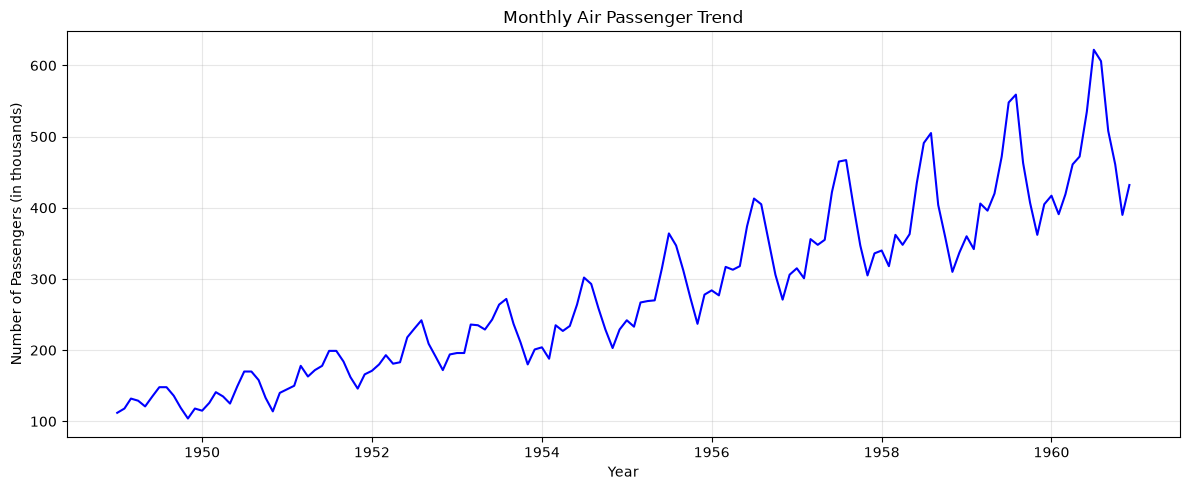


6-7. SEASONAL DECOMPOSITION


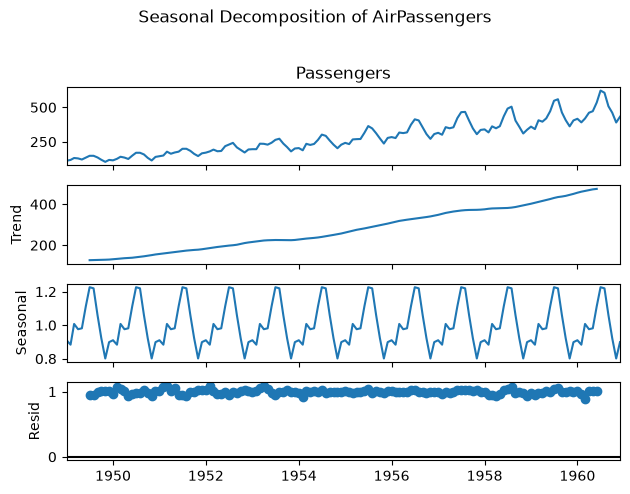

In [3]:
print("=" * 60)
print("\n1. FIRST FIVE OBSERVATIONS")
print(ts.head().to_string())
print("\n2. LAST FIVE OBSERVATIONS")
print(ts.tail().to_string())
print("\n3-4. TIME SERIES CHARACTERISTICS")
print("Start period:", ts.index.min().strftime("%Y-%m"))
print("End period:", ts.index.max().strftime("%Y-%m"))
print("Frequency: 12 observations per year (monthly)")
print("Class: pandas.Series")
print("Number of observations:", len(ts))
print("Time interval:", ts.index.freqstr)
print("\nSUMMARY STATISTICS")
print(ts.describe().to_string())
print("\n5. MONTHLY PASSENGER TREND")
plt.figure(figsize=(12, 5))
plt.plot(ts.index, ts.values, color="blue")
plt.title("Monthly Air Passenger Trend")
plt.xlabel("Year")
plt.ylabel("Number of Passengers (in thousands)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("\n6-7. SEASONAL DECOMPOSITION")
decomp = seasonal_decompose(ts, model="multiplicative", period=12)
decomp.plot()
plt.suptitle("Seasonal Decomposition of AirPassengers", y=1.02)
plt.tight_layout()


8. AUTOCORRELATION FUNCTION (ACF)


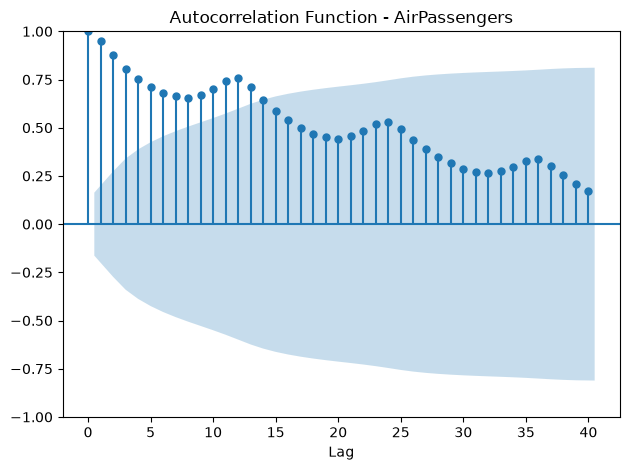


8. PARTIAL AUTOCORRELATION FUNCTION (PACF)


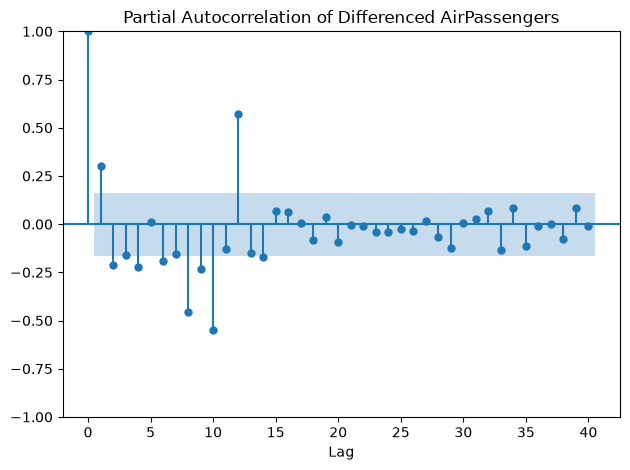


9-10. FITTING ARIMA(1,1,1) MODEL

ARIMA(1,1,1) MODEL SUMMARY
                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  144
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -694.341
Date:                Wed, 28 Oct 2026   AIC                           1394.683
Time:                        19:50:51   BIC                           1403.571
Sample:                    01-01-1949   HQIC                          1398.294
                         - 12-01-1960                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.4742      0.123     -3.847      0.000      -0.716      -0.233
ma.L1          0.8635      0.078     11.051      0.000       0.710   

In [4]:
plt.show()
print("\n8. AUTOCORRELATION FUNCTION (ACF)")
plot_acf(ts, lags=40)
plt.title("Autocorrelation Function - AirPassengers")
plt.xlabel("Lag")
plt.tight_layout()
plt.show()
print("\n8. PARTIAL AUTOCORRELATION FUNCTION (PACF)")
plot_pacf(ts.diff().dropna(), lags=40, method="ywm")
plt.title("Partial Autocorrelation of Differenced AirPassengers")
plt.xlabel("Lag")
plt.tight_layout()
plt.show()
print("\n9-10. FITTING ARIMA(1,1,1) MODEL")
model = ARIMA(ts, order=(1, 1, 1)).fit()
print("\nARIMA(1,1,1) MODEL SUMMARY")
print(model.summary())
print("\n11. FORECAST FOR THE NEXT 12 MONTHS")
pred = model.get_forecast(steps=12)
forecast = pred.predicted_mean
ci = pred.conf_int()
forecast_table = pd.DataFrame({
    "Forecast": forecast,
    "Lower 95% CI": ci.iloc[:, 0],
    "Upper 95% CI": ci.iloc[:, 1]
})
print(forecast_table.round(2).to_string())
print("\n12. ACTUAL VS FORECASTED PASSENGER VALUES")

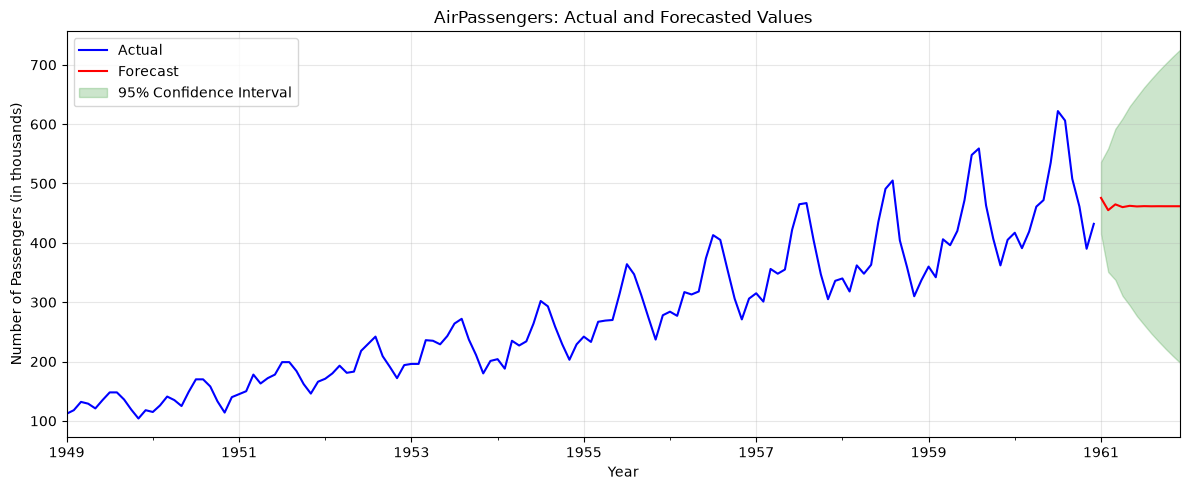

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
ts.plot(ax=ax, label="Actual", color="blue")
forecast.plot(ax=ax, label="Forecast", color="red")
ax.fill_between(
    ci.index,
    ci.iloc[:, 0].to_numpy(),
    ci.iloc[:, 1].to_numpy(),
    color="green",
    alpha=0.2,
    label="95% Confidence Interval"
)
ax.set_title("AirPassengers: Actual and Forecasted Values")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Passengers (in thousands)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()